In [1]:
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


data_dir = Path(
    "/work/magroup/skrieger/Syndri/data/datasets/"
    "breast_xenium/results/final"
)

files = sorted(data_dir.glob("*.h5ad"))
print(f"Found {len(files)} breast Xenium slices")

Found 19 breast Xenium slices


In [2]:
rctd_columns = [
    "rctd_spot_class",
    "rctd_first_type",
    "rctd_second_type",
    "rctd_first_weight",
    "rctd_second_weight",
]

frames = []

for path in files:
    adata = ad.read_h5ad(path, backed="r")

    missing = [c for c in rctd_columns if c not in adata.obs]
    if missing:
        adata.file.close()
        raise KeyError(f"{path.name} is missing columns: {missing}")

    frame = adata.obs[rctd_columns].copy().reset_index()
    frame = frame.rename(columns={"index": "cell_id"})
    frame["slice"] = path.stem

    frames.append(frame)
    adata.file.close()

rctd = pd.concat(frames, ignore_index=True)

# Normalize missing secondary annotations.
missing_strings = {"", "nan", "none", "na", "<na>"}

secondary_string = rctd["rctd_second_type"].astype(str).str.strip()
valid_secondary = (
    rctd["rctd_second_type"].notna()
    & ~secondary_string.str.lower().isin(missing_strings)
)

rctd["has_secondary_type"] = valid_secondary
rctd.loc[~valid_secondary, "rctd_second_type"] = pd.NA

# Ensure weights are numeric.
rctd["rctd_first_weight"] = pd.to_numeric(
    rctd["rctd_first_weight"],
    errors="coerce",
)
rctd["rctd_second_weight"] = pd.to_numeric(
    rctd["rctd_second_weight"],
    errors="coerce",
)

print(f"{len(rctd):,} cells across {rctd['slice'].nunique()} slices")
rctd.head()

1,673,926 cells across 19 slices


,cell_id,rctd_spot_class,rctd_first_type,rctd_second_type,rctd_first_weight,rctd_second_weight,slice,has_secondary_type
0,GSM9509156_breast_breast_B17_B17:aaabdoaf-1,doublet_certain,capillary endothelial cell,smooth muscle cell,0.486629,0.513371,GSM9509156_breast_breast_B17_B17_rctd_annotated,True
1,GSM9509156_breast_breast_B17_B17:aaaembmd-1,doublet_certain,capillary endothelial cell,smooth muscle cell,0.477185,0.522815,GSM9509156_breast_breast_B17_B17_rctd_annotated,True
2,GSM9509156_breast_breast_B17_B17:aaagfnfh-1,doublet_certain,capillary endothelial cell,fibroblast of lung,0.550117,0.449883,GSM9509156_breast_breast_B17_B17_rctd_annotated,True
3,GSM9509156_breast_breast_B17_B17:aaagolie-1,doublet_certain,pericyte,smooth muscle cell,0.446629,0.553371,GSM9509156_breast_breast_B17_B17_rctd_annotated,True
4,GSM9509156_breast_breast_B17_B17:aaailmpi-1,singlet,fibroblast of lung,<NA>,1.000000,0.000000,GSM9509156_breast_breast_B17_B17_rctd_annotated,False


In [3]:
spot_class_counts = (
    rctd.groupby("rctd_spot_class", observed=True)
    .size()
    .rename("n_cells")
    .reset_index()
)

spot_class_counts["frequency"] = (
    spot_class_counts["n_cells"]
    / spot_class_counts["n_cells"].sum()
)

spot_class_counts = spot_class_counts.sort_values(
    "frequency",
    ascending=False,
)

spot_class_counts

,rctd_spot_class,n_cells,frequency
4,singlet,1233787,0.737062
0,doublet_certain,390465,0.233263
1,doublet_uncertain,32389,0.019349
3,reject,16811,0.010043
2,rctd_filtered,474,0.000283


In [10]:
spot_class_by_slice = (
    rctd.groupby(
        ["slice", "rctd_spot_class"],
        observed=True,
    )
    .size()
    .rename("n_cells")
    .reset_index()
)

spot_class_by_slice["frequency"] = (
    spot_class_by_slice["n_cells"]
    / spot_class_by_slice.groupby("slice")["n_cells"].transform("sum")
)

spot_class_by_slice.head()

,slice,rctd_spot_class,n_cells,frequency
0,GSM9509156_breast_breast_B17_B17_rctd_annotated,doublet_certain,10181,0.149323
1,GSM9509156_breast_breast_B17_B17_rctd_annotated,doublet_uncertain,427,0.006263
2,GSM9509156_breast_breast_B17_B17_rctd_annotated,rctd_filtered,11,0.000161
3,GSM9509156_breast_breast_B17_B17_rctd_annotated,reject,387,0.005676
4,GSM9509156_breast_breast_B17_B17_rctd_annotated,singlet,57175,0.838577


In [4]:
weight_summary = (
    rctd.groupby("slice", observed=True)
    .agg(
        n_cells=("cell_id", "size"),
        primary_weight_median=("rctd_first_weight", "median"),
        primary_weight_q25=(
            "rctd_first_weight",
            lambda x: x.quantile(0.25),
        ),
        primary_weight_q75=(
            "rctd_first_weight",
            lambda x: x.quantile(0.75),
        ),
        secondary_weight_median=("rctd_second_weight", "median"),
        secondary_weight_q25=(
            "rctd_second_weight",
            lambda x: x.quantile(0.25),
        ),
        secondary_weight_q75=(
            "rctd_second_weight",
            lambda x: x.quantile(0.75),
        ),
        n_with_secondary=("has_secondary_type", "sum"),
    )
    .reset_index()
)

weight_summary["fraction_with_secondary"] = (
    weight_summary["n_with_secondary"]
    / weight_summary["n_cells"]
)

weight_summary

,slice,n_cells,primary_weight_median,primary_weight_q25,primary_weight_q75,secondary_weight_median,secondary_weight_q25,secondary_weight_q75,n_with_secondary,fraction_with_secondary
0,GSM9509156_breast_breast_B17_B17_rctd_annotated,68181,1.0,1.000000,1.0,0.0,0.0,0.000000,11006,0.161423
1,GSM9509157_breast_breast_B16_B16_rctd_annotated,15990,1.0,0.685996,1.0,0.0,0.0,0.314004,5756,0.359975
2,GSM9509158_breast_breast_B15_B15_rctd_annotated,33494,1.0,1.000000,1.0,0.0,0.0,0.000000,3976,0.118708
3,GSM9509159_breast_breast_B14_B14_rctd_annotated,77383,1.0,0.746972,1.0,0.0,0.0,0.253028,24001,0.310159
4,GSM9509160_breast_breast_B2_B2_rctd_annotated,130957,1.0,1.000000,1.0,0.0,0.0,0.000000,12965,0.099002
5,GSM9509161_breast_breast_B13_B13_rctd_annotated,37542,1.0,1.000000,1.0,0.0,0.0,0.000000,5009,0.133424
6,GSM9509162_breast_breast_B12_B12_rctd_annotated,151364,1.0,1.000000,1.0,0.0,0.0,0.000000,35314,0.233305
7,GSM9509163_breast_breast_B11_B11_rctd_annotated,79547,1.0,1.000000,1.0,0.0,0.0,0.000000,10832,0.136171
8,GSM9509164_breast_breast_B10_B10_rctd_annotated,66079,1.0,0.701666,1.0,0.0,0.0,0.298334,24158,0.365593
9,GSM9509165_breast_breast_B4_B4_rctd_annotated,37902,1.0,0.735954,1.0,0.0,0.0,0.264046,13210,0.348530


In [5]:
secondary_cells = rctd.loc[
    rctd["has_secondary_type"]
    & rctd["rctd_second_weight"].notna()
].copy()

secondary_weight_summary = (
    secondary_cells.groupby("slice", observed=True)
    ["rctd_second_weight"]
    .describe(
        percentiles=[0.25, 0.5, 0.75]
    )
)

secondary_weight_summary

,count,mean,std,min,25%,50%,75%,max
slice,,,,,,,,
GSM9509156_breast_breast_B17_B17_rctd_annotated,10995.0,0.385862,0.130135,0.058766,0.288523,0.377169,0.482625,0.907841
GSM9509157_breast_breast_B16_B16_rctd_annotated,5748.0,0.391628,0.138972,0.048194,0.290335,0.386480,0.487789,0.904443
GSM9509158_breast_breast_B15_B15_rctd_annotated,3959.0,0.412761,0.145487,0.080823,0.295241,0.401948,0.527948,0.900936
GSM9509159_breast_breast_B14_B14_rctd_annotated,24001.0,0.361553,0.116098,0.037955,0.276689,0.361832,0.443444,0.932503
GSM9509160_breast_breast_B2_B2_rctd_annotated,12885.0,0.405026,0.120646,0.048205,0.321514,0.404516,0.486622,0.930146
GSM9509161_breast_breast_B13_B13_rctd_annotated,4981.0,0.418669,0.116842,0.017922,0.343907,0.419513,0.488114,0.960704
GSM9509162_breast_breast_B12_B12_rctd_annotated,35291.0,0.377238,0.121488,0.039270,0.289792,0.379001,0.462095,0.895367
GSM9509163_breast_breast_B11_B11_rctd_annotated,10704.0,0.427746,0.145710,0.039349,0.323648,0.422246,0.523669,0.928300
GSM9509164_breast_breast_B10_B10_rctd_annotated,24155.0,0.361995,0.126309,0.047473,0.270740,0.362924,0.452889,0.902202


In [6]:
secondary_type_counts = (
    secondary_cells.groupby("rctd_second_type", observed=True)
    .size()
    .rename("n_cells")
    .reset_index()
)

secondary_type_counts["frequency_among_secondary"] = (
    secondary_type_counts["n_cells"]
    / secondary_type_counts["n_cells"].sum()
)

secondary_type_counts["frequency_among_all_cells"] = (
    secondary_type_counts["n_cells"]
    / len(rctd)
)

secondary_type_counts = secondary_type_counts.sort_values(
    "frequency_among_secondary",
    ascending=False,
)

secondary_type_counts

,rctd_second_type,n_cells,frequency_among_secondary,frequency_among_all_cells
5,fibroblast of lung,96535,0.219565,0.057670
7,malignant cell,78280,0.178045,0.046764
6,macrophage,65457,0.148879,0.039104
14,smooth muscle cell,31949,0.072667,0.019086
3,cytotoxic T cell,22234,0.050570,0.013283
4,fibroblast of breast,21199,0.048216,0.012664
11,pericyte,20233,0.046019,0.012087
13,plasmacytoid dendritic cell,19725,0.044864,0.011784
1,capillary endothelial cell,18057,0.041070,0.010787
12,plasma cell,14930,0.033958,0.008919


In [9]:
secondary_type_by_slice = (
    secondary_cells.groupby(
        ["slice", "rctd_second_type"],
        observed=True,
    )
    .size()
    .rename("n_cells")
    .reset_index()
)

secondary_type_by_slice["frequency_among_secondary"] = (
    secondary_type_by_slice["n_cells"]
    / secondary_type_by_slice
        .groupby("slice")["n_cells"]
        .transform("sum")
)

secondary_type_by_slice.head()

,slice,rctd_second_type,n_cells,frequency_among_secondary
0,GSM9509156_breast_breast_B17_B17_rctd_annotated,"CD4-positive, alpha-beta memory T cell",144,0.013097
1,GSM9509156_breast_breast_B17_B17_rctd_annotated,capillary endothelial cell,418,0.038017
2,GSM9509156_breast_breast_B17_B17_rctd_annotated,classical monocyte,384,0.034925
3,GSM9509156_breast_breast_B17_B17_rctd_annotated,cytotoxic T cell,441,0.040109
4,GSM9509156_breast_breast_B17_B17_rctd_annotated,fibroblast of breast,93,0.008458


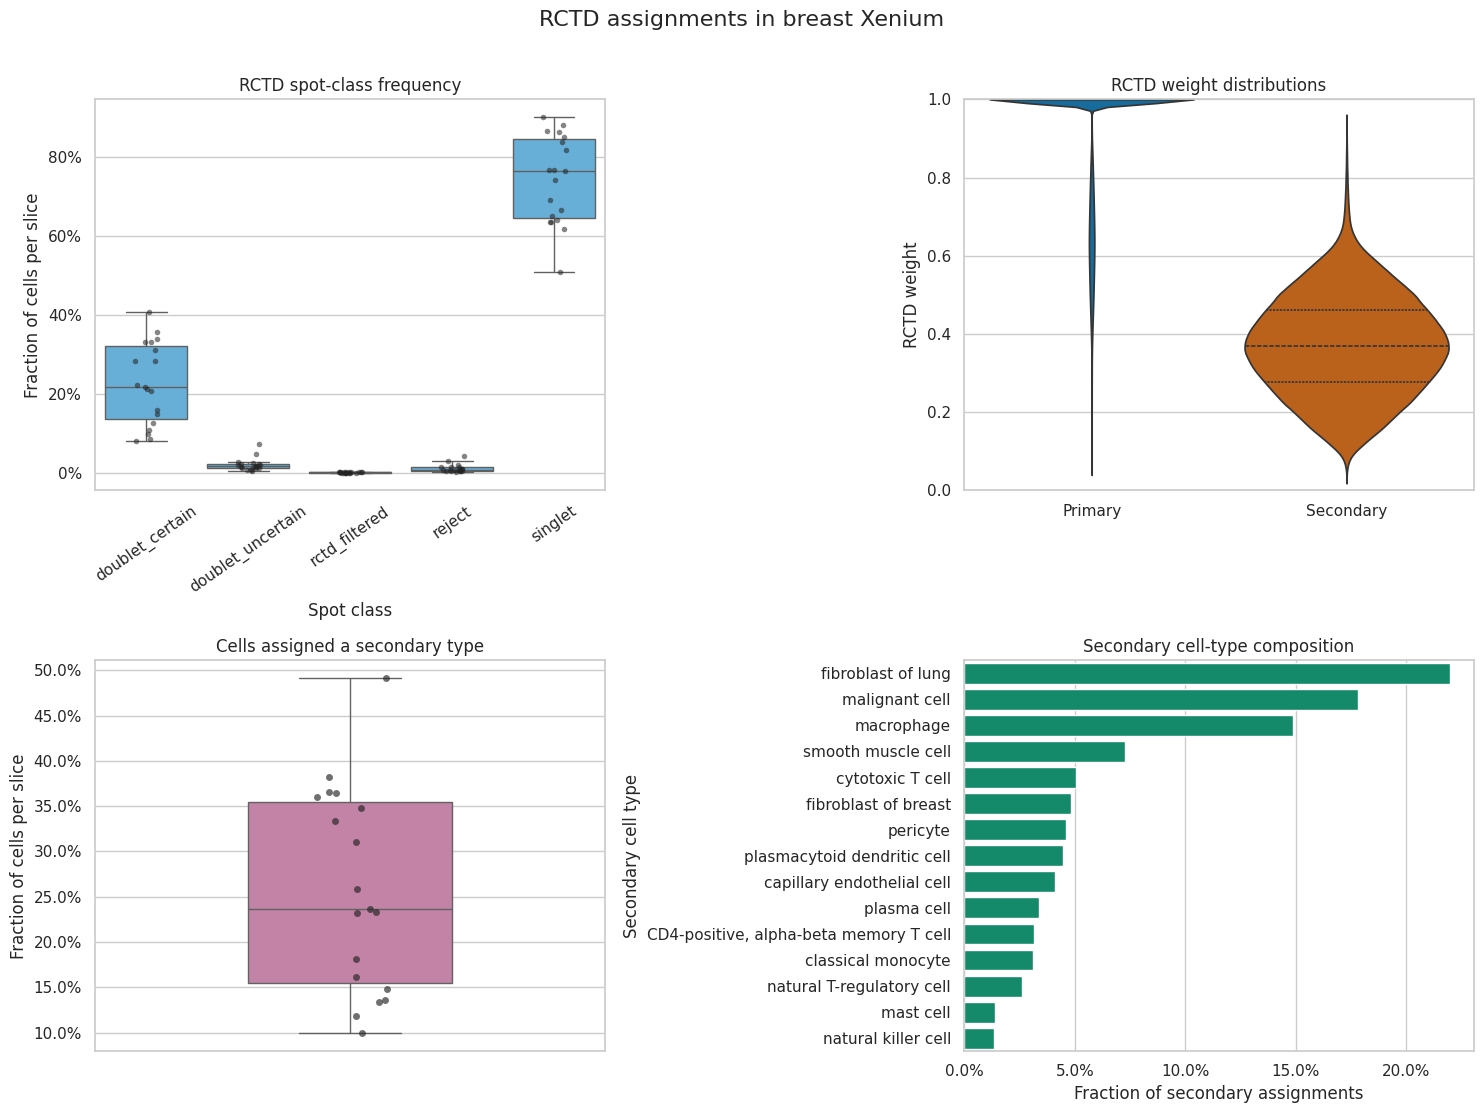

In [11]:
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 11),
)

# A: spot-class frequencies per slice.
sns.boxplot(
    data=spot_class_by_slice,
    x="rctd_spot_class",
    y="frequency",
    color="#56B4E9",
    showfliers=False,
    ax=axes[0, 0],
)

sns.stripplot(
    data=spot_class_by_slice,
    x="rctd_spot_class",
    y="frequency",
    color="#222222",
    alpha=0.55,
    size=4,
    jitter=0.12,
    ax=axes[0, 0],
)

axes[0, 0].set_title("RCTD spot-class frequency")
axes[0, 0].set_xlabel("Spot class")
axes[0, 0].set_ylabel("Fraction of cells per slice")
axes[0, 0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0, 0].tick_params(axis="x", rotation=35)


# B: primary and secondary weight distributions.
weights_long = pd.concat(
    [
        rctd.loc[
            rctd["rctd_first_weight"].notna(),
            ["slice", "rctd_first_weight"],
        ].rename(columns={"rctd_first_weight": "weight"}).assign(
            weight_type="Primary"
        ),
        secondary_cells.loc[
            :,
            ["slice", "rctd_second_weight"],
        ].rename(columns={"rctd_second_weight": "weight"}).assign(
            weight_type="Secondary"
        ),
    ],
    ignore_index=True,
)

sns.violinplot(
    data=weights_long,
    x="weight_type",
    y="weight",
    hue="weight_type",
    palette={
        "Primary": "#0072B2",
        "Secondary": "#D55E00",
    },
    inner="quartile",
    cut=0,
    legend=False,
    ax=axes[0, 1],
)

axes[0, 1].set_title("RCTD weight distributions")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("RCTD weight")
axes[0, 1].set_ylim(0, 1)


# C: fraction of cells with a secondary type.
secondary_fraction = (
    rctd.groupby("slice", observed=True)["has_secondary_type"]
    .mean()
    .reset_index(name="frequency")
)

sns.boxplot(
    data=secondary_fraction,
    y="frequency",
    color="#CC79A7",
    width=0.4,
    showfliers=False,
    ax=axes[1, 0],
)

sns.stripplot(
    data=secondary_fraction,
    y="frequency",
    color="#222222",
    alpha=0.65,
    size=5,
    jitter=0.08,
    ax=axes[1, 0],
)

axes[1, 0].set_title("Cells assigned a secondary type")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Fraction of cells per slice")
axes[1, 0].yaxis.set_major_formatter(PercentFormatter(1))


# D: secondary-type frequencies.
secondary_order = (
    secondary_type_counts["rctd_second_type"]
    .astype(str)
    .tolist()
)

sns.barplot(
    data=secondary_type_counts,
    y="rctd_second_type",
    x="frequency_among_secondary",
    order=secondary_order,
    color="#009E73",
    ax=axes[1, 1],
)

axes[1, 1].set_title("Secondary cell-type composition")
axes[1, 1].set_xlabel("Fraction of secondary assignments")
axes[1, 1].set_ylabel("Secondary cell type")
axes[1, 1].xaxis.set_major_formatter(PercentFormatter(1))

fig.suptitle(
    "RCTD assignments in breast Xenium",
    fontsize=16,
    y=1.01,
)

fig.tight_layout()
plt.show()

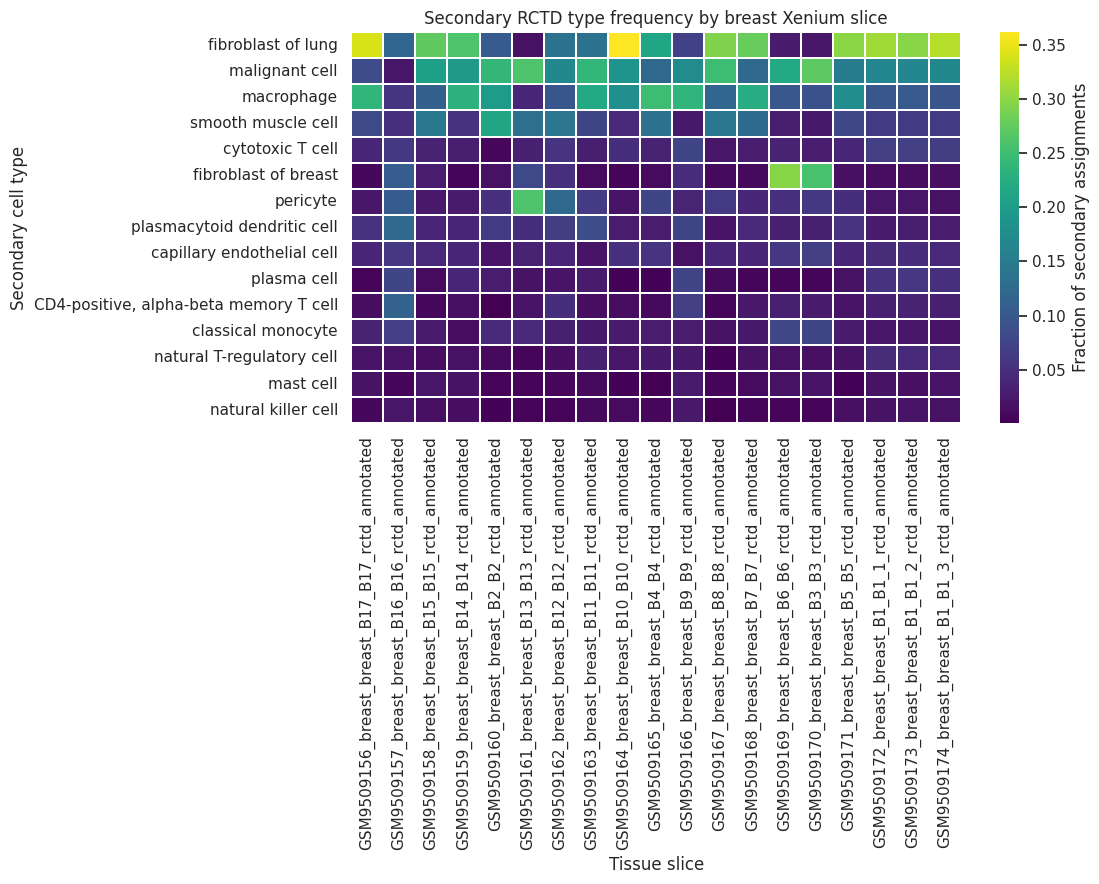

In [14]:
secondary_heatmap = (
    secondary_type_by_slice.pivot(
        index="rctd_second_type",
        columns="slice",
        values="frequency_among_secondary",
    )
    .fillna(0)
)

# Order types by their total number of assignments.
type_order = secondary_type_counts["rctd_second_type"]
secondary_heatmap = secondary_heatmap.reindex(type_order)

plt.figure(
    figsize=(
        max(10, 0.6 * secondary_heatmap.shape[1]),
        max(6, 0.6 * secondary_heatmap.shape[0]),
    )
)

sns.heatmap(
    secondary_heatmap,
    cmap="viridis",
    linewidths=0.2,
    cbar_kws={"label": "Fraction of secondary assignments"},
)

plt.title("Secondary RCTD type frequency by breast Xenium slice")
plt.xlabel("Tissue slice")
plt.ylabel("Secondary cell type")
plt.tight_layout()
plt.show()